## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 
import os
os.chdir("/Users/lior/uueda/uu_markov/data")

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

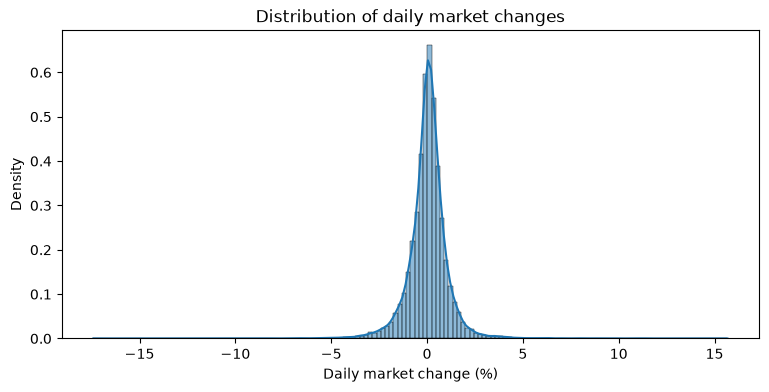

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

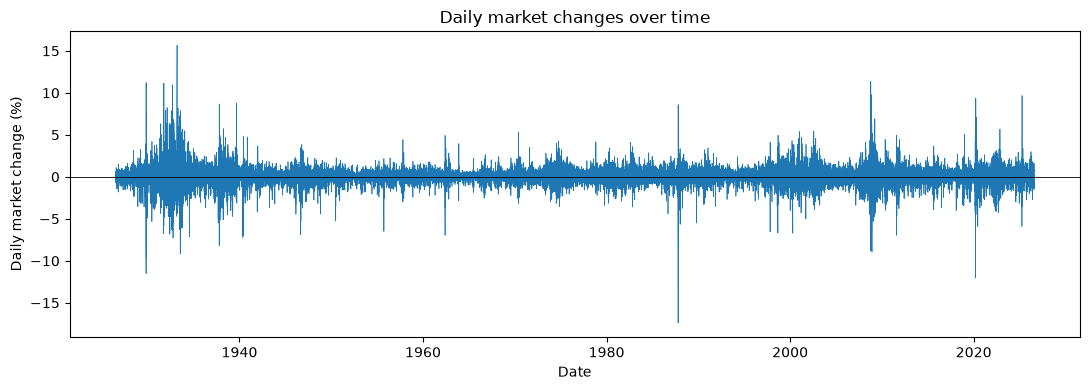

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [6]:
df['r_t'] = df['market_return_pct']
df['r_tp1'] =df['market_return_pct'].shift(-1)
d2 =df.dropna(subset=['r_tp1']).copy() 
d2['s_t']= np.where(d2.r_t> 0, 'Up', 'Down')
d2['s_tp1']= np.where(d2.r_tp1> 0, 'Up', 'Down')

joint2 = pd.crosstab(d2.s_t, d2.s_tp1, normalize='all')
print("Joint PMF (rows: today, cols:tomorrow)"); display(joint2.round(3))
print("Marginal today:\n",joint2.sum(axis=1).round(3))
print("Marginal tomorrow:\n",joint2.sum(axis=0).round(3))
cond2 =pd.crosstab(d2.s_t, d2.s_tp1, normalize='index')
print("Conditional PMF P(tomorrow | today)"); display(cond2.round(3))

Joint PMF (rows: today, cols:tomorrow)


s_tp1,Down,Up
s_t,,
Down,0.225,0.228
Up,0.228,0.319


Marginal today:
 s_t
Down    0.453
Up      0.547
dtype: float64
Marginal tomorrow:
 s_tp1
Down    0.453
Up      0.547
dtype: float64
Conditional PMF P(tomorrow | today)


s_tp1,Down,Up
s_t,,
Down,0.496,0.504
Up,0.417,0.583


up days are more common that down and flat days. its more likely to have an up day tomorrow if there was an up day to day, more than it would be after having a down day by 58% so it helps in predicting a little but not by a lot.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [7]:
bins   = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['large loss', 'small loss', 'near zero','small gain','large gain']
d5 = df.dropna(subset=['r_tp1']).copy()
d5['c_t']= pd.cut(d5.r_t,   bins=bins, labels=labels)
d5['c_tp1']= pd.cut(d5.r_tp1, bins=bins, labels=labels)
print(d5.c_t.value_counts().reindex(labels))
joint5= pd.crosstab(d5.c_t, d5.c_tp1, normalize='all')
print("Joint PMF"); display(joint5.round(3))
cond5 =pd.crosstab(d5.c_t, d5.c_tp1, normalize='index')
print("Conditional PMF"); display(cond5.round(3))
print("Top two next states for each current state:")
for s in labels:
    print(f"{s:11s} ->", list(cond5.loc[s].nlargest(2).round(3).items()))
print("Next-day return by current state:")
display(d5.groupby('c_t', observed=True)['r_tp1'].describe().round(3))

c_t
large loss    2759
small loss    7452
near zero     3441
small gain    9784
large gain    2859
Name: count, dtype: int64
Joint PMF


c_tp1,large loss,small loss,near zero,small gain,large gain
c_t,,,,,
large loss,0.021,0.027,0.009,0.028,0.020
small loss,0.035,0.089,0.034,0.098,0.027
near zero,0.009,0.042,0.021,0.049,0.009
small gain,0.025,0.100,0.055,0.159,0.033
large gain,0.014,0.026,0.012,0.038,0.020


Conditional PMF


c_tp1,large loss,small loss,near zero,small gain,large gain
c_t,,,,,
large loss,0.203,0.259,0.086,0.265,0.186
small loss,0.125,0.313,0.121,0.345,0.097
near zero,0.071,0.321,0.160,0.377,0.071
small gain,0.067,0.269,0.148,0.428,0.088
large gain,0.127,0.235,0.107,0.348,0.183


Top two next states for each current state:
large loss  -> [('small gain', 0.265), ('small loss', 0.259)]
small loss  -> [('small gain', 0.345), ('small loss', 0.313)]
near zero   -> [('small gain', 0.377), ('small loss', 0.321)]
small gain  -> [('small gain', 0.428), ('small loss', 0.269)]
large gain  -> [('small gain', 0.348), ('small loss', 0.235)]
Next-day return by current state:


,count,mean,std,min,25%,50%,75%,max
c_t,,,,,,,,
large loss,2759.0,-0.038,1.721,-17.41,-0.79,-0.01,0.72,11.22
small loss,7452.0,-0.044,1.010,-11.23,-0.53,0.01,0.45,11.36
near zero,3441.0,0.015,0.826,-8.19,-0.35,0.03,0.42,5.49
small gain,9784.0,0.107,0.832,-8.25,-0.25,0.12,0.50,8.67
large gain,2859.0,0.163,1.384,-12.00,-0.37,0.15,0.73,15.67


small loss, near zero, and small gain have the most days. large loss and large gain seem to be the rarest. transitions are most likely to occur between the three common middle states. each row is different from a uniform .2 value but that might be because of the fact that the bins arent equally populated and not because of the predictability. the same three states are probably going to be the next states everywhere. the conditional mean values of tomorrows return for every state are very small so the direction would be hard to predict. but after a large loss/gain, tomorrows min/max are widest and the SD is highest, and after near zero its the lowest which is all the volatility we see where there are big moves that are followed by more big moves and calm days are followed by calm days.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

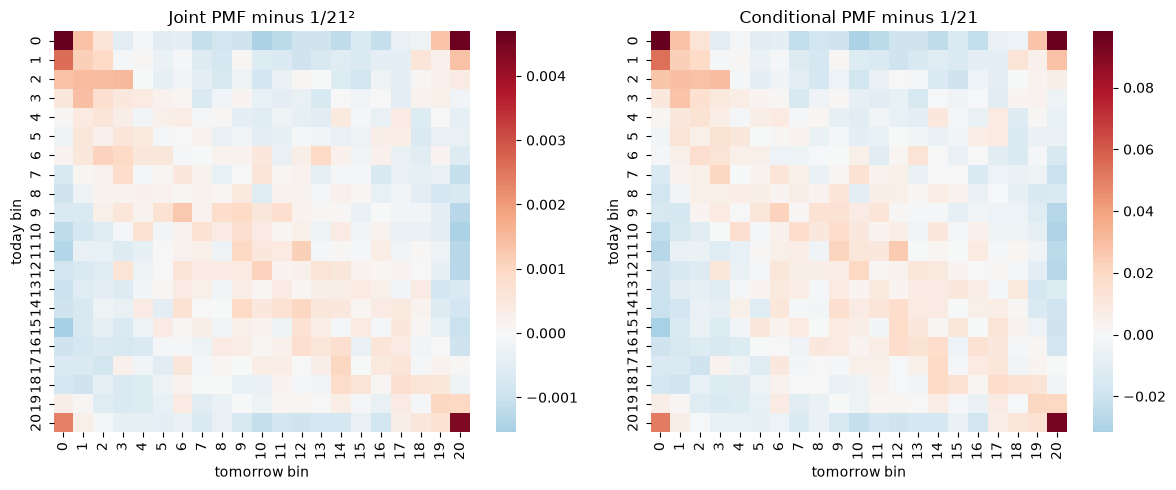

In [8]:
d21 = df.copy()
d21['y_t']   = pd.qcut(d21.r_t, 21, labels=False)
d21['y_tp1'] = d21['y_t'].shift(-1)
d21 = d21.dropna(subset=['y_tp1']).copy()
d21['y_tp1'] = d21['y_tp1'].astype(int)

joint21 = pd.crosstab(d21.y_t, d21.y_tp1, normalize='all')
cond21  = pd.crosstab(d21.y_t, d21.y_tp1, normalize='index')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(joint21 - 1/21**2, center=0, cmap='RdBu_r', ax=axes[0])
axes[0].set(title='Joint PMF minus 1/21²', xlabel='tomorrow bin', ylabel='today bin')
sns.heatmap(cond21 - 1/21, center=0, cmap='RdBu_r', ax=axes[1])
axes[1].set(title='Conditional PMF minus 1/21', xlabel='tomorrow bin', ylabel='today bin')
plt.tight_layout();
plt.show()

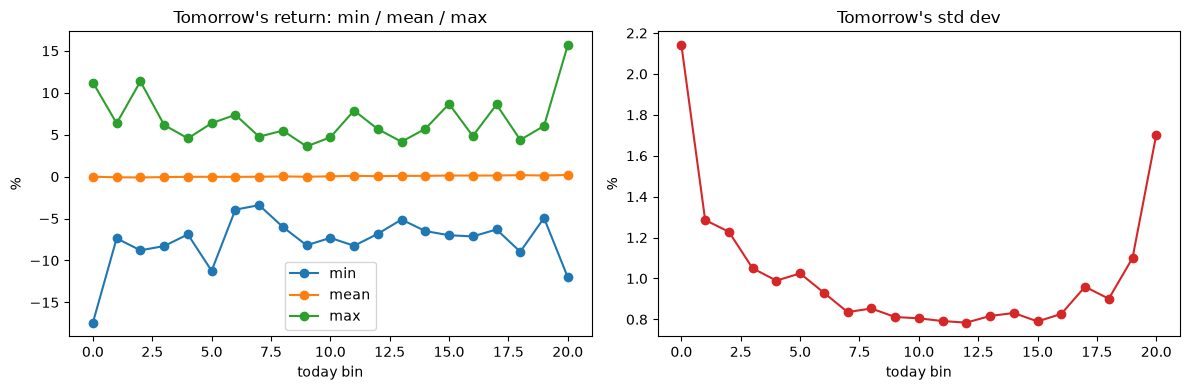

In [ ]:
g = d21.groupby('y_t')['r_tp1'].agg(['min', 'mean', 'max', 'std'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
g[['min', 'mean', 'max']].plot(ax=axes[0], marker='o')
axes[0].set(title="Tomorrow's return: min / mean / max", xlabel='today bin', ylabel='%')
g['std'].plot(ax=axes[1], marker='o', color='C3')
axes[1].set(title="Tomorrow's std dev", xlabel='today bin', ylabel='%')
plt.tight_layout();
plt.show()

after removing the baseline the excess probability mostly is concentrated in the corners and the deficit in the off corner cells. the bins are equal probability by construction so any pattern deviates from uniformly random behavior.
the rows for the lowest and highest bins are u shaped which means theres more mass on extreme next day bins and less in the middle. the middle rows have mire mass in the middle so its the opposite byt the pattern is symmetric and depends on the size of todays move.
the mean of tommorrows return is basically flat across bins while min and max fan out a lot. the standard deviation is u shaped and highest after the biggest losses and gains and lowest after small moves.

i dont think its easy to predict the market but risk and volatility is which is what the markov chain tells you.